# 호출 한도와 재시도·폴백

**이 노트북에서 할 일**

1. 시간 제한을 아주 짧게 준 모델로 재시도 미들웨어가 몇 번 다시 부르는지 셉니다.
2. 존재하지 않는 모델 이름으로 폴백 미들웨어가 예비 모델로 넘어가는지 확인합니다.
3. 호출 한도를 1번으로 두고 도구가 필요한 질문을 보내 실행이 멈추는지 확인합니다.

**준비물** — `.env` 파일의 `OPENAI_API_KEY`. 데이터 파일은 없습니다. 모델 호출 요청은 6번이고 그중 정상 응답은 2번입니다. 실행 시간은 1분 이내이고, 예상 비용은 0.01달러 미만입니다.

## 오늘 볼 그림

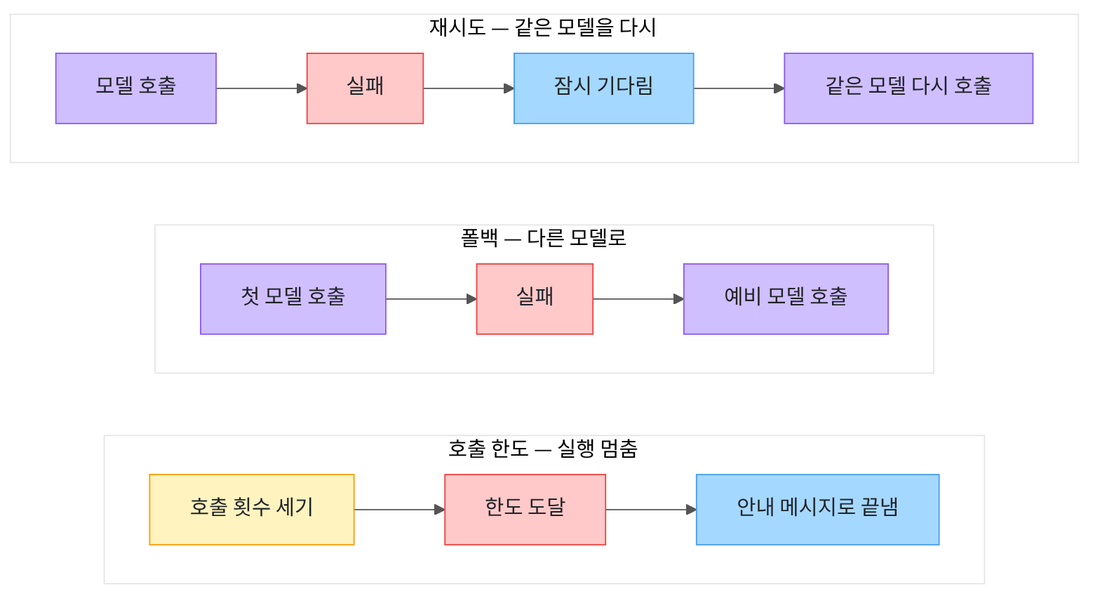

위에서부터 재시도, 폴백, 호출 한도입니다. 재시도는 같은 모델을 다시 부르고, 폴백은 다른 모델로 바꾸고, 호출 한도는 실행을 멈춥니다.

## 1. 준비

첫 셀은 패키지를 설치하고 설치된 버전을 출력합니다. 설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-openai==1.6.0" "langgraph==1.2.11" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-openai:", version("langchain-openai"))
print("langgraph:", version("langgraph"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-openai: 1.6.0
langgraph: 1.2.11


이번 절에서 쓰는 이름을 불러옵니다. 재시도·폴백·호출 한도 미들웨어 세 개가 들어 있습니다.

In [2]:
# 에이전트·미들웨어·도구·모델을 만드는 도구를 불러옵니다
from collections.abc import Callable

from langchain.agents import create_agent
from langchain.agents.middleware import ModelCallLimitMiddleware, ModelFallbackMiddleware, ModelRetryMiddleware
from langchain.agents.middleware import ModelRequest, ModelResponse, wrap_model_call
from langchain.chat_models import init_chat_model
from langchain.tools import tool

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다. 01절과 같은 설정입니다.
temperature 값을 0으로 두어 매번 비슷한 답을 고르게 합니다.

In [4]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-15에 이 모델로 실행한 결과입니다.

## 2. 시도 기록 훅 만들기

이번 절에서는 모델 호출이 실패하는 상황을 실제로 만듭니다. 시도가 몇 번 있었는지 세려면 기록 훅이 필요합니다.
이 훅은 모델을 부를 때마다 모델 이름을 `attempts` 목록에 적습니다.

In [5]:
# 모델을 부를 때마다 모델 이름을 적는 훅을 만듭니다
attempts = []


@wrap_model_call
def record_attempt(request: ModelRequest, handler: Callable) -> ModelResponse:
    attempts.append(request.model.model_name)
    return handler(request)

출력은 없습니다.

## 3. 재시도 — 같은 모델을 다시 부르기

재시도(retry)는 실패한 호출을 같은 모델에 다시 보내는 방법입니다. 네트워크가 잠깐 느릴 때 쓸모가 있습니다.

실패를 일부러 만들기 위해 시간 제한(`timeout`)을 0.001초로 줍니다. 이 시간 안에는 응답이 올 수 없습니다.
인자 `max_retries=0`은 모델 객체가 스스로 다시 시도하지 않게 합니다. 재시도는 미들웨어에만 맡깁니다.

In [6]:
# 0.001초 안에 응답해야 하는 모델을 만듭니다(반드시 시간 초과가 납니다)
slow_model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
    timeout=0.001,
    max_retries=0,
)
print("시간 제한(초):", slow_model.request_timeout)

시간 제한(초): 0.001


**결과 읽기** — 시간 제한이 `0.001`초로 설정됐습니다.

`ModelRetryMiddleware()` 클래스의 `max_retries=2`는 처음 시도가 실패하면 두 번 더 시도하라는 뜻입니다.
인자 `initial_delay=0.5`는 첫 재시도 전에 0.5초 기다린다는 뜻입니다.
기다리는 시간은 재시도할 때마다 두 배가 되므로 두 번째 재시도 전에는 1초입니다. 대기 시간은 이번에 재지 않습니다.
인자 `jitter=False`는 기다리는 시간에 무작위 값을 더하지 않게 합니다.

먼저 등록한 미들웨어가 바깥에서 감쌉니다. 그래서 재시도는 안쪽의 기록 훅과 모델을 함께 다시 부릅니다.
재시도 미들웨어를 기록 훅보다 앞에 두어야 다시 시도할 때마다 기록 훅도 실행됩니다.

In [7]:
# 재시도 미들웨어를 등록하고 질문을 보냅니다
retry = ModelRetryMiddleware(max_retries=2, initial_delay=0.5, jitter=False)
retry_agent = create_agent(slow_model, tools=[], middleware=[retry, record_attempt])
question = {"messages": [{"role": "user", "content": "자료실 운영 시간을 알려 주세요."}]}
retry_result = retry_agent.invoke(question)
last_message = retry_result["messages"][-1]
print("시도 횟수:", len(attempts))
print("마지막 메시지:", last_message.text)

시도 횟수: 3
마지막 메시지: Model call failed after 3 attempts with OpenAITimeoutError: Request timed out.


**결과 읽기** — 시도 횟수는 `3`입니다. 처음 1번과 재시도 2번입니다.
세 번 모두 시간 초과였기 때문에 마지막 메시지는 답이 아니라 실패 안내입니다.
재시도는 원인이 사라지지 않으면 결과를 바꾸지 못합니다. 이번 조건은 매번 시간 초과가 나도록 만들었습니다.

In [8]:
# 재시도 횟수를 확인하고, 다음 실험을 위해 기록을 비웁니다
retry_attempts = len(attempts)
assert retry_attempts == 3
attempts.clear()
print("비운 뒤 기록 개수:", len(attempts))

비운 뒤 기록 개수: 0


**결과 읽기** — 비운 뒤 기록 개수는 `0`입니다.

## 4. 폴백 — 다른 모델로 넘어가기

폴백(fallback)은 첫 모델이 실패하면 예비 모델로 바꿔 부르는 방법입니다. 모델 서비스 한 곳에 장애가 났을 때 씁니다.
실패를 만들기 위해 존재하지 않는 모델 이름을 씁니다. 예비 모델은 더 작은 `gpt-5.4-nano`입니다.

In [9]:
# 존재하지 않는 이름의 모델과, 대신 쓸 예비 모델을 만듭니다
broken_model = init_chat_model("openai:gpt-no-such-model", temperature=0, max_retries=0)
backup_model = init_chat_model("openai:gpt-5.4-nano", temperature=0, reasoning_effort="none")
print("첫 모델:", broken_model.model_name)
print("예비 모델:", backup_model.model_name)

첫 모델: gpt-no-such-model
예비 모델: gpt-5.4-nano


**결과 읽기** — 첫 모델 이름은 `gpt-no-such-model`, 예비 모델 이름은 `gpt-5.4-nano`입니다.

`ModelFallbackMiddleware()` 클래스에 예비 모델을 넘깁니다. 이번에도 기록 훅을 뒤에 둡니다.
마지막 메시지의 `response_metadata` 속성에는 답한 모델 이름 같은 응답 정보가 들어 있습니다.

In [10]:
# 폴백 미들웨어를 등록하고 질문을 보냅니다
fallback = ModelFallbackMiddleware(backup_model)
fallback_agent = create_agent(broken_model, tools=[], middleware=[fallback, record_attempt])
greeting = {"messages": [{"role": "user", "content": "한 문장으로 인사해 주세요."}]}
fallback_result = fallback_agent.invoke(greeting)
last_message = fallback_result["messages"][-1]
print("시도한 모델 순서:", attempts)
print("답한 모델:", last_message.response_metadata["model_name"])

시도한 모델 순서: ['gpt-no-such-model', 'gpt-5.4-nano']
답한 모델: gpt-5.4-nano-2026-03-17


**결과 읽기** — 시도한 모델 순서가 `gpt-no-such-model` 다음 `gpt-5.4-nano`입니다.
답한 모델도 nano 모델입니다. 첫 모델이 실패하자 미들웨어가 요청의 모델만 바꿔 다시 불렀습니다.

In [11]:
# 폴백 순서를 확인하고, 다음 실험을 위해 기록을 비웁니다
# list()로 복사본을 만들어 두면 원본을 비워도 순서가 남습니다
fallback_order = list(attempts)
assert fallback_order == ["gpt-no-such-model", "gpt-5.4-nano"]
attempts.clear()
print("비운 뒤 기록 개수:", len(attempts))

비운 뒤 기록 개수: 0


**결과 읽기** — 비운 뒤 기록 개수는 `0`입니다.

## 5. 호출 한도 — 실행 멈추기

호출 한도(call limit)는 한 번 실행하는 동안 모델을 부를 수 있는 횟수의 상한입니다.
모델이 도구를 끝없이 부르는 반복을 막을 때 씁니다. 01절의 운영 시간 도구를 다시 만듭니다.

In [12]:
# 자료실 운영 시간을 알려 주는 도구를 만듭니다
@tool
def lookup_hours(day: str) -> str:
    """자료실 운영 시간을 조회합니다. day에는 "평일" 또는 "토요일"을 넣습니다."""
    if day == "평일":
        return "평일 09:00~20:00"
    return "토요일 10:00~17:00"


print("도구 이름:", lookup_hours.name)

도구 이름: lookup_hours


**결과 읽기** — 도구 이름 `lookup_hours`가 출력됩니다.

인자 `run_limit=1`은 한 번 실행하는 동안 모델을 1번만 부르라는 뜻입니다.
도구가 필요한 질문은 모델을 최소 2번 불러야 합니다. 도구 요청에 1번, 최종 답에 1번입니다. 그래서 두 번째 호출에서 멈출 것입니다.
인자 `exit_behavior="end"`는 한도에 걸리면 오류를 내지 않고 안내 메시지로 끝내라는 뜻입니다.

In [13]:
# 모델 호출을 1번으로 제한하고 도구가 필요한 질문을 보냅니다
limit = ModelCallLimitMiddleware(run_limit=1, exit_behavior="end")
limit_agent = create_agent(model, tools=[lookup_hours], middleware=[limit, record_attempt])
tool_question = "반드시 lookup_hours 도구로 확인한 뒤 자료실 평일 운영 시간을 알려 주세요."
limit_result = limit_agent.invoke({"messages": [{"role": "user", "content": tool_question}]})
print("모델 호출 횟수:", len(attempts))
for message in limit_result["messages"]:
    print(message.type, "|", message.text)

모델 호출 횟수: 1
human | 반드시 lookup_hours 도구로 확인한 뒤 자료실 평일 운영 시간을 알려 주세요.
ai | 
tool | 평일 09:00~20:00
ai | Model call limits exceeded: run limit (1/1)


**결과 읽기** — 모델 호출 횟수는 `1`입니다. 마지막 메시지는 `Model call limits exceeded`로 시작하는 안내입니다.
첫 호출에서 모델이 도구를 요청했고 도구도 실행됐습니다. 그러나 도구 결과를 읽을 두 번째 모델 호출은 한도에 걸려 실행되지 않았습니다.

In [14]:
# 세 실험의 결과를 한 번에 출력합니다
limit_calls = len(attempts)
print("재시도 — 시도 횟수:", retry_attempts)
print("폴백 — 시도한 모델:", fallback_order)
print("호출 한도 — 모델 호출 횟수:", limit_calls)
assert limit_calls == 1

재시도 — 시도 횟수: 3
폴백 — 시도한 모델: ['gpt-no-such-model', 'gpt-5.4-nano']
호출 한도 — 모델 호출 횟수: 1


**결과 읽기** — 재시도는 `3`번 시도, 폴백은 두 모델을 차례로 시도, 호출 한도는 `1`번 호출에서 멈췄습니다.

## 정리

- 재시도는 같은 모델을 다시 부릅니다. 실패 원인이 그대로면 횟수만 늘어납니다.
- 폴백은 다른 모델로 바꿔 부릅니다. 한 모델 서비스의 장애에 대비합니다.
- 호출 한도는 정해진 횟수를 넘으면 실행을 멈춥니다. 끝없는 반복과 비용 증가를 막습니다.